# Positive-Sample Coverage Check (buffer-then-clip)

**Goal.** Confirm every REE positive sample sits inside its region outline **and** has real data in **all** modeling input layers, once GLCM rasters are read with an outward buffer so near-edge windows draw on genuine (nation-wide) data rather than clip-edge nodata.

No erosion, no before/after comparison. Just: *buffer-clip the rasters -> build the common valid mask -> clip it back to the true outline -> check each positive against every layer.*

## 1. Configuration (reused verbatim from the modeling notebook)

In [1]:
import os, warnings
warnings.filterwarnings('ignore')
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import matplotlib.patches as mpatches
import rasterio
from rasterio.mask import mask as rio_mask
from rasterio.warp import reproject, Resampling
from rasterio.transform import rowcol as rio_rowcol
import scipy.ndimage as ndi
from scipy.cluster.hierarchy import linkage, fcluster
import pyproj

BASE = '../dataset'

_RASTERS = {
    'gravity_ba':          f'{BASE}/converted getech data/Gravity_converted/Canada_BA.flt',
    'gravity_ba_1vd':      f'{BASE}/converted getech data/Gravity_converted/Canada_BA_1VD.flt',
    'gravity_ba_hp100km':  f'{BASE}/converted getech data/Gravity_converted/Canada_BA_HP100km.flt',
    'gravity_ba_hp40km':   f'{BASE}/converted getech data/Gravity_converted/Canada_BA_HP40km.flt',
    'gravity_ba_thd':      f'{BASE}/converted getech data/Gravity_converted/Canada_BA_THD.flt',
    'gravity_ba_thd_tilt': f'{BASE}/converted getech data/Gravity_converted/Canada_BA_THD_Tilt.flt',
    'mag_drtp':            f'{BASE}/converted getech data/Magnetic_converted/DRTP.flt',
    'mag_drtp_1vd':        f'{BASE}/converted getech data/Magnetic_converted/DRTP_1VD.flt',
    'mag_drtp_thd':        f'{BASE}/converted getech data/Magnetic_converted/DRTP_THD.flt',
    'mag_drtp_thd_tilt':   f'{BASE}/converted getech data/Magnetic_converted/DRTP_THD_Tilt.flt',
    'mag_tmi':             f'{BASE}/converted getech data/Magnetic_converted/TMI.flt',
    'gravity_up30km':      f'{BASE}/new USGS data/GeophysicsGravity_Up30km_USCanada.tif',
    'gravity_up30km_hgm':  f'{BASE}/new USGS data/GeophysicsGravity_Up30km_HGM_USCanada.tif',
    'lab_depth':           f'{BASE}/new USGS data/GeophysicsLAB_USCanada.tif',
    'mag_rtp_deep':        f'{BASE}/new USGS data/USCanadaMagRTP_DeepSources.tif',
    'mag_rtp_hgm_deep':    f'{BASE}/new USGS data/USCanadaMagRTP_HGMDeepSources.tif',
    'moho_depth':          f'{BASE}/new USGS data/USCanada_Moho.tif',
}

REGIONS = {
    'Cordilleran': {
        'dep':     'Cordilleran_REE_deposits_deduped_2.0km.csv',
        'outline': f'{BASE}/3_areas/Cordilleran.geojson',
        'raster':  _RASTERS,
    },
    'Superior': {
        'dep':     'Superior_REE_deposits_deduped_2.0km.csv',
        'outline': f'{BASE}/3_areas/Superior.geojson',
        'raster':  _RASTERS,
    },
    'Grenville': {
        'dep':     'Grenville_REE_deposits_deduped_2.0km.csv',
        'outline': f'{BASE}/3_areas/Grenville.geojson',
        'raster':  _RASTERS,
    },
}

PROJECTED_CRS = 'EPSG:3978'   # Canada Atlas Lambert (metres)
BUFFER_KM     = 10.0          # min distance from any REE deposit -> negative sample
GRID_DEG      = 0.1           # ~10 km grid spacing for negative sampling & prediction
RANDOM_SEED   = 42
POSITIVE_DEDUP_RADIUS_KM = 0  # matches the source notebook (already-deduped positive CSVs)

GLCM_RASTERS    = ['gravity_ba', 'mag_tmi', 'mag_drtp', 'gravity_ba_hp40km']
GLCM_PATCH_HALF = 4            # 9x9-pixel GLCM window, same constant as the source notebook

ALL_MODEL_RASTERS = list(_RASTERS.keys())
REFERENCE_RASTER_KEY = 'gravity_ba'  # coarsest of the 4 GLCM rasters (2 km) -- see intro markdown

print(f'{len(ALL_MODEL_RASTERS)} modeling rasters (gravity all + magnetic all + moho + lab):')
print(' ', ALL_MODEL_RASTERS)
print(f'GLCM_RASTERS={GLCM_RASTERS}  GLCM_PATCH_HALF={GLCM_PATCH_HALF}  '
      f'reference grid={REFERENCE_RASTER_KEY!r}')

17 modeling rasters (gravity all + magnetic all + moho + lab):
  ['gravity_ba', 'gravity_ba_1vd', 'gravity_ba_hp100km', 'gravity_ba_hp40km', 'gravity_ba_thd', 'gravity_ba_thd_tilt', 'mag_drtp', 'mag_drtp_1vd', 'mag_drtp_thd', 'mag_drtp_thd_tilt', 'mag_tmi', 'gravity_up30km', 'gravity_up30km_hgm', 'lab_depth', 'mag_rtp_deep', 'mag_rtp_hgm_deep', 'moho_depth']
GLCM_RASTERS=['gravity_ba', 'mag_tmi', 'mag_drtp', 'gravity_ba_hp40km']  GLCM_PATCH_HALF=4  reference grid='gravity_ba'


## 2. `clip_raster` helper (reused verbatim)

In [2]:
CLIP_DIR = 'clipped'

def clip_raster(src_path, boundary_gdf, out_path):
    with rasterio.open(src_path) as src:
        bnd = boundary_gdf.to_crs(src.crs) if src.crs else boundary_gdf
        shapes = [g.__geo_interface__ for g in bnd.geometry]
        out_img, out_tf = rio_mask(src, shapes, crop=True)
        meta = src.meta.copy()
        meta.update(driver='GTiff', height=out_img.shape[1],
                    width=out_img.shape[2], transform=out_tf)
    os.makedirs(os.path.dirname(out_path), exist_ok=True)
    with rasterio.open(out_path, 'w', **meta) as dst:
        dst.write(out_img)

print('clip_raster ready.')

clip_raster ready.


## 3. `make_points` (reused verbatim) -- the same positives the pipeline uses

In [3]:
def haversine_km(lat1, lon1, lat2, lon2):
    R = 6371.0
    lat1,lon1,lat2,lon2 = map(np.radians,[lat1,lon1,lat2,lon2])
    dlat,dlon = lat2-lat1, lon2-lon1
    a = np.sin(dlat/2)**2 + np.cos(lat1)*np.cos(lat2)*np.sin(dlon/2)**2
    return 2*R*np.arcsin(np.sqrt(a))


def dedup_close_positives(dep_in, radius_km):
    """Unchanged from the source notebook. radius_km<=0/None disables this
    (POSITIVE_DEDUP_RADIUS_KM=0 here, matching the source notebook, since
    the *_REE_deposits_deduped_2.0km.csv positive tables are already
    deduplicated externally -- this is a no-op)."""
    if not radius_km or radius_km <= 0 or len(dep_in) < 2:
        return dep_in
    proj = dep_in.to_crs(PROJECTED_CRS)
    coords = np.column_stack([proj.geometry.x.values, proj.geometry.y.values])
    cluster_ids = fcluster(linkage(coords, method='single', metric='euclidean'),
                           t=radius_km * 1000.0, criterion='distance')
    keep_idx = []
    for cid in np.unique(cluster_ids):
        idx = np.where(cluster_ids == cid)[0]
        if len(idx) == 1:
            keep_idx.append(idx[0])
            continue
        centroid = coords[idx].mean(axis=0)
        rep = idx[np.argmin(np.linalg.norm(coords[idx] - centroid, axis=1))]
        keep_idx.append(rep)
    return dep_in.iloc[sorted(keep_idx)].reset_index(drop=True)


def make_points(cfg, rng):
    """Unchanged from the source notebook (byte-for-byte copy)."""
    boundary = gpd.read_file(cfg['outline']).to_crs('EPSG:4326')
    study_area = boundary.unary_union

    dep = pd.read_csv(cfg['dep']).dropna(subset=['Latitude','Longitude'])
    dep_gdf = gpd.GeoDataFrame(dep,
        geometry=gpd.points_from_xy(dep['Longitude'], dep['Latitude']),
        crs='EPSG:4326')
    dep_in = dep_gdf[dep_gdf.within(study_area)].reset_index(drop=True)
    if len(dep_in) == 0:
        raise ValueError('No REE deposits found within the study area outline.')
    dep_in = dedup_close_positives(dep_in, POSITIVE_DEDUP_RADIUS_KM)

    pos = pd.DataFrame({'lat': dep_in.geometry.y, 'lon': dep_in.geometry.x, 'label': 1})
    dlat = dep_in.geometry.y.values
    dlon = dep_in.geometry.x.values

    xmin, ymin, xmax, ymax = boundary.total_bounds
    xs = np.arange(xmin, xmax, GRID_DEG)
    ys = np.arange(ymin, ymax, GRID_DEG)
    xx, yy = np.meshgrid(xs, ys)
    grid_gdf = gpd.GeoDataFrame(
        geometry=gpd.points_from_xy(xx.ravel(), yy.ravel()), crs='EPSG:4326')
    grid_in = grid_gdf[grid_gdf.within(study_area)].copy()
    grid_in['lat'] = grid_in.geometry.y
    grid_in['lon'] = grid_in.geometry.x

    glat = grid_in['lat'].values
    glon = grid_in['lon'].values
    min_dep_dist = np.array([
        haversine_km(glat[i], glon[i], dlat, dlon).min()
        for i in range(len(glat))
    ])
    candidates = grid_in[min_dep_dist > BUFFER_KM][['lat','lon']].copy()
    candidates['label'] = -1

    pts = pd.concat([pos[['lat','lon','label']], candidates], ignore_index=True)
    print(f'  Positive: {len(pos)}  |  Candidates: {len(candidates)}')
    return pts

print('make_points ready (unmodified copy).')

make_points ready (unmodified copy).


## 4. Buffer-then-clip the national rasters

Each original nation-wide raster is clipped to the region outline **buffered outward by `BUFFER_KM_GLCM`** (buffer computed once in `PROJECTED_CRS`, the polygon then reprojected per raster inside `clip_raster`). This guarantees a full GLCM window of real data around every in-outline point.

In [4]:
BUFFER_KM_GLCM = 8.0                      # >= GLCM window half-width in ground units
CLIP_DIR_BUFFERED = 'clipped_buffered'

def preprocess_rasters_buffered(name, cfg, buffer_km):
    boundary_native   = gpd.read_file(cfg['outline']).to_crs('EPSG:4326')
    boundary_buffered = gpd.GeoDataFrame(
        geometry=boundary_native.to_crs(PROJECTED_CRS).buffer(buffer_km * 1000.0),
        crs=PROJECTED_CRS).to_crs('EPSG:4326')

    out_dir = os.path.join(CLIP_DIR_BUFFERED, name)
    os.makedirs(out_dir, exist_ok=True)
    clipped = {}
    for feat, path in cfg.get('raster', {}).items():
        out_path = os.path.join(out_dir, f'{feat}.tif')
        if not os.path.exists(out_path):
            print(f'  clipping {feat} (buffered +{buffer_km:.0f}km) ...')
            clip_raster(path, boundary_buffered, out_path)
        clipped[feat] = out_path
    return clipped

print(f'Buffering outlines by {BUFFER_KM_GLCM:.0f} km then clipping the national rasters ...')
CLIPPED_RASTERS_BUFFERED = {}
for name, cfg in REGIONS.items():
    print(f'\n[{name}]')
    CLIPPED_RASTERS_BUFFERED[name] = preprocess_rasters_buffered(name, cfg, BUFFER_KM_GLCM)
print('\nDone.')

Buffering outlines by 8 km then clipping the national rasters ...

[Cordilleran]

[Superior]

[Grenville]

Done.


## 5. Common valid mask -- all layers have real data (no erosion)

For each region: build a per-layer validity mask on the coarsest GLCM raster's grid (`REFERENCE_RASTER_KEY`), AND them into a **common valid mask** (a pixel is valid only if *every* modeling layer has data there), then clip that mask back to the **true, unbuffered outline**. No erosion: a positive only needs real data in every layer, not distance from the edge.

In [5]:
from rasterio.features import geometry_mask as rio_geometry_mask

def load_valid_mask_native(path):
    with rasterio.open(path) as src:
        data = src.read(1).astype(float)
        nd = src.nodata
        valid = (data != nd) & np.isfinite(data) if nd is not None else np.isfinite(data)
        return valid, src.transform, src.crs

def reproject_mask_to_reference(valid_native, src_tf, src_crs, ref_tf, ref_crs, ref_shape):
    dst = np.zeros(ref_shape, dtype=np.uint8)
    reproject(source=valid_native.astype(np.uint8), destination=dst,
              src_transform=src_tf, src_crs=src_crs,
              dst_transform=ref_tf, dst_crs=ref_crs, resampling=Resampling.nearest)
    return dst.astype(bool)

def build_common_valid_mask(clipped_rasters):
    ref_path = clipped_rasters[REFERENCE_RASTER_KEY]
    with rasterio.open(ref_path) as ref_src:
        ref_tf, ref_crs, ref_shape = ref_src.transform, ref_src.crs, ref_src.shape
    per_layer = {}
    common = np.ones(ref_shape, dtype=bool)
    for key in ALL_MODEL_RASTERS:
        vnat, stf, scrs = load_valid_mask_native(clipped_rasters[key])
        von = reproject_mask_to_reference(vnat, stf, scrs, ref_tf, ref_crs, ref_shape)
        per_layer[key] = von
        common &= von
    return ref_tf, ref_crs, ref_shape, common, per_layer

def clip_mask_to_outline(mask, ref_tf, ref_crs, outline_path):
    boundary = gpd.read_file(outline_path).to_crs(ref_crs)
    outline_mask = rio_geometry_mask(boundary.geometry, out_shape=mask.shape,
                                     transform=ref_tf, invert=True)
    return mask & outline_mask

print('Mask functions ready (no erosion).')

Mask functions ready (no erosion).


## 6. Build masks and generate points for all regions

In [6]:
rng = np.random.default_rng(RANDOM_SEED)
COV = {}
for name, cfg in REGIONS.items():
    print(f'\n{"="*66}\n[{name}]\n{"="*66}')
    ref_tf, ref_crs, ref_shape, common_buf, per_layer_buf = build_common_valid_mask(
        CLIPPED_RASTERS_BUFFERED[name])
    common_final = clip_mask_to_outline(common_buf, ref_tf, ref_crs, cfg['outline'])

    pts = make_points(cfg, rng)
    pos = pts[pts['label'] == 1].reset_index(drop=True)

    COV[name] = dict(ref_tf=ref_tf, ref_crs=ref_crs, ref_shape=ref_shape,
                     common_final=common_final, per_layer_buf=per_layer_buf,
                     pos=pos, cand=pts[pts['label'] == -1].reset_index(drop=True))
print('\nAll regions processed.')


[Cordilleran]
  Positive: 28  |  Candidates: 22724

[Superior]
  Positive: 15  |  Candidates: 19702

[Grenville]
  Positive: 12  |  Candidates: 8752

All regions processed.


## 7. Per-positive coverage check across **every** input layer

For each positive, look up its pixel on the reference grid and record, for every modeling layer, whether that layer has real data there. `all_layers_ok` is the bottom line.

In [7]:
def positive_layer_coverage(name):
    d = COV[name]
    ref_tf, ref_crs, ref_shape = d['ref_tf'], d['ref_crs'], d['ref_shape']
    per_layer = d['per_layer_buf']
    pos = d['pos']
    H, W = ref_shape

    tr = pyproj.Transformer.from_crs('EPSG:4326', ref_crs, always_xy=True)
    xs, ys = tr.transform(pos['lon'].values, pos['lat'].values)
    rows, cols = rio_rowcol(ref_tf, xs, ys)
    rows = np.asarray(rows); cols = np.asarray(cols)

    recs = []
    for i in range(len(pos)):
        r, c = rows[i], cols[i]
        in_grid = (0 <= r < H) and (0 <= c < W)
        rec = {'region': name, 'lat': pos.loc[i, 'lat'], 'lon': pos.loc[i, 'lon']}
        if 'Name' in pos.columns:
            rec['Name'] = pos.loc[i, 'Name']
        if not in_grid:
            rec['in_outline_common'] = False
            rec['all_layers_ok'] = False
            rec['missing_layers'] = 'OUT_OF_GRID'
            recs.append(rec); continue
        missing = [k for k, m in per_layer.items() if not m[r, c]]
        rec['in_outline_common'] = bool(d['common_final'][r, c])
        rec['all_layers_ok'] = (len(missing) == 0)
        rec['missing_layers'] = '' if not missing else ', '.join(missing)
        recs.append(rec)
    return pd.DataFrame(recs)

pd.set_option('display.width', 170)
pd.set_option('display.max_colwidth', 60)
coverage_df = pd.concat([positive_layer_coverage(n) for n in REGIONS], ignore_index=True)

cols = [c for c in ['region','Name','lat','lon','in_outline_common','all_layers_ok','missing_layers']
        if c in coverage_df.columns]
coverage_df = coverage_df[cols]

print('Positives with a missing layer (should be empty):')
bad = coverage_df[~coverage_df['all_layers_ok']]
print('  NONE -- every positive has data in all layers.' if bad.empty else bad.to_string(index=False))

Positives with a missing layer (should be empty):
  NONE -- every positive has data in all layers.


## 8. Per-region summary

In [8]:
summary = (coverage_df
           .groupby('region')
           .agg(n_positives=('all_layers_ok', 'size'),
                n_all_layers_ok=('all_layers_ok', 'sum'))
           .reset_index())
summary['n_missing_some_layer'] = summary['n_positives'] - summary['n_all_layers_ok']
print(summary.to_string(index=False))

total_bad = int((~coverage_df['all_layers_ok']).sum())
print('\nRESULT:', 'ALL positives fully covered across all layers.' if total_bad == 0
      else f'{total_bad} positive(s) still missing at least one layer -- inspect above.')

     region  n_positives  n_all_layers_ok  n_missing_some_layer
Cordilleran           28               28                     0
  Grenville           12               12                     0
   Superior           15               15                     0

RESULT: ALL positives fully covered across all layers.


## 9. Per-region map -- positives on the common valid domain

Green = common valid domain (all layers present) inside the outline. Positives that pass the coverage check are blue stars; any that fail are red X.

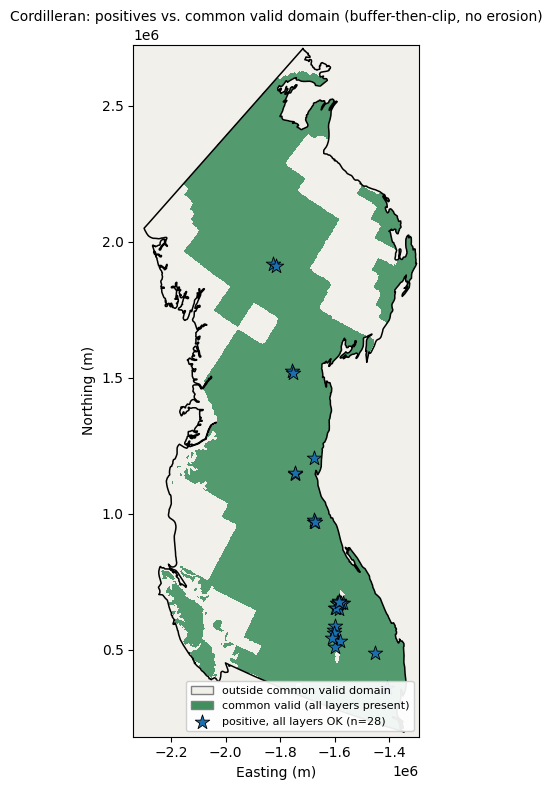

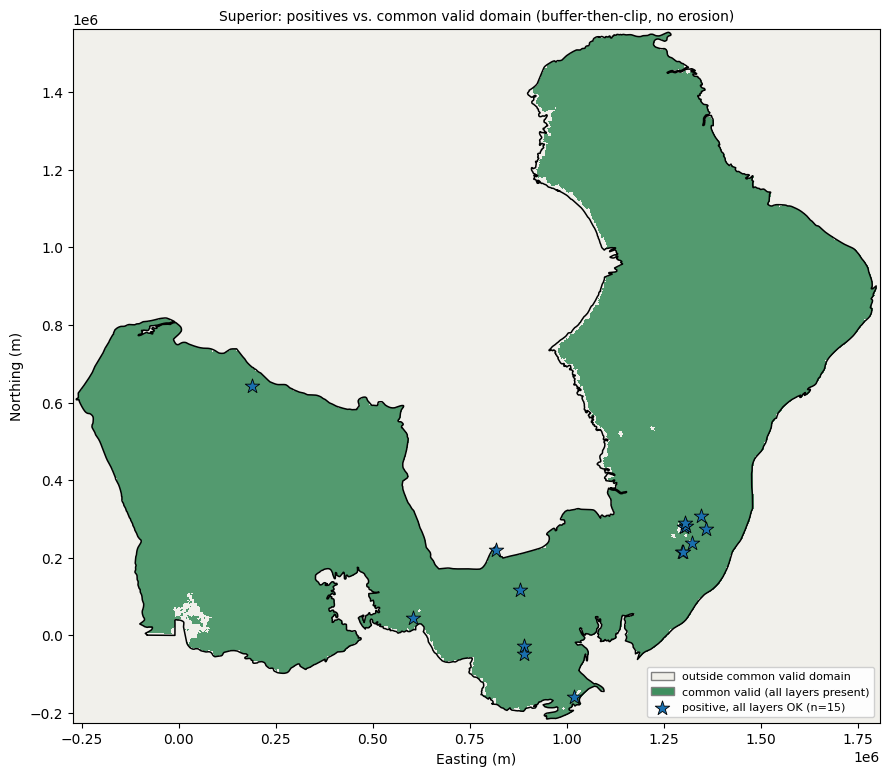

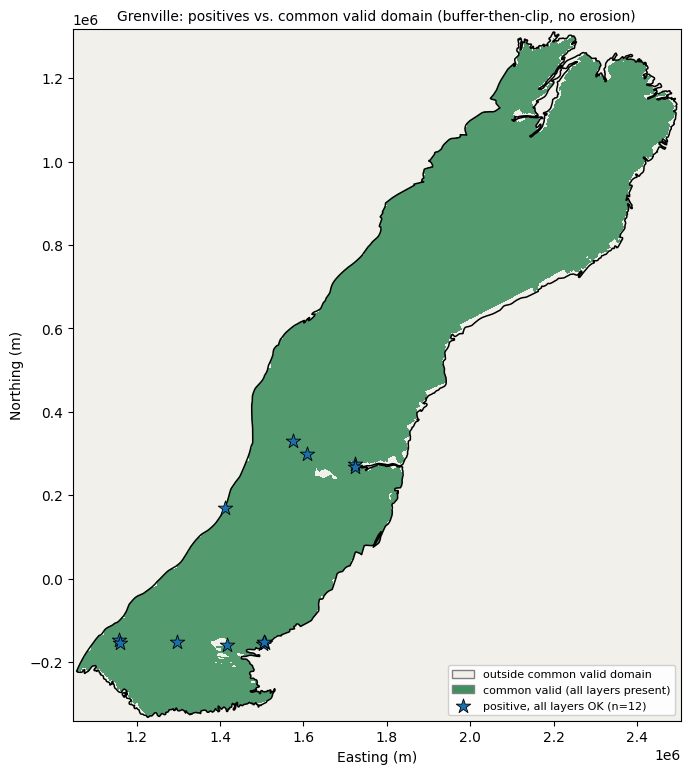

In [9]:
def plot_region(name):
    d = COV[name]
    ref_tf, shape = d['ref_tf'], d['ref_shape']
    H, W = shape
    extent = [ref_tf.c, ref_tf.c + W * ref_tf.a, ref_tf.f + H * ref_tf.e, ref_tf.f]

    fig, ax = plt.subplots(figsize=(9, 8))
    ax.imshow(d['common_final'].astype(int), extent=extent, origin='upper',
              cmap=mcolors.ListedColormap(['#f0efe9', '#3f8f5f']), vmin=0, vmax=1, alpha=0.9)

    boundary = gpd.read_file(REGIONS[name]['outline']).to_crs(PROJECTED_CRS)
    for geom in boundary.geometry:
        polys = [geom] if geom.geom_type == 'Polygon' else list(geom.geoms)
        for poly in polys:
            gx, gy = poly.exterior.xy
            ax.plot(gx, gy, 'k-', lw=1.1)

    tr = pyproj.Transformer.from_crs('EPSG:4326', PROJECTED_CRS, always_xy=True)
    cov = positive_layer_coverage(name)
    ok = cov['all_layers_ok'].values
    px_, py_ = tr.transform(cov['lon'].values, cov['lat'].values)
    ax.scatter(px_[ok], py_[ok], s=120, marker='*', c='#1a6faf',
               edgecolors='black', linewidths=0.6, zorder=5,
               label=f'positive, all layers OK (n={int(ok.sum())})')
    if (~ok).any():
        ax.scatter(px_[~ok], py_[~ok], s=140, marker='X', c='#d73027',
                   edgecolors='black', linewidths=0.8, zorder=6,
                   label=f'positive, missing a layer (n={int((~ok).sum())})')

    legend_extra = [
        mpatches.Patch(facecolor='#f0efe9', edgecolor='grey', label='outside common valid domain'),
        mpatches.Patch(facecolor='#3f8f5f', edgecolor='grey', label='common valid (all layers present)'),
    ]
    h, l = ax.get_legend_handles_labels()
    ax.legend(handles=legend_extra + h, loc='lower right', fontsize=8, framealpha=0.92)
    ax.set_title(f'{name}: positives vs. common valid domain (buffer-then-clip, no erosion)', fontsize=10)
    ax.set_xlabel('Easting (m)'); ax.set_ylabel('Northing (m)'); ax.set_aspect('equal')
    plt.tight_layout(); plt.show()

for name in REGIONS:
    plot_region(name)

---

## 10. Condition B — GLCM computability mask

Condition A (above) only checks that a pixel has real data in all 17
modeling layers *at that single pixel*. It says nothing about whether a
9x9 GLCM window **centered** there would actually have enough valid
neighbours -- that is a separate, stricter question, and is what excluded
`Goéland` / `Martison Lake` / `Megiscane Lake` / `St. Honoré` /
`Terres Rompues - Se` in the erosion-based diagnostic this notebook
replaces.

`build_glcm_ok_mask` computes, for **each of the 4 `GLCM_RASTERS`
separately, on that raster's own native grid/CRS/resolution** (buffer-then-
clip, no shared reference grid for this step): a per-pixel boolean "does
this pixel's own `(2*GLCM_PATCH_HALF+1)^2` window contain `>= min_valid`
real valid pixels" via a box-sum (`scipy.ndimage.uniform_filter`,
`mode='constant', cval=0`). Padding beyond a raster's own array with `0`
(invalid) for this box-sum is not an approximation here -- for a **count**
threshold (`valid_count >= min_valid`, not a *ratio*), it is mathematically
identical to `add_glcm_features`'s own boundary-clamped smaller window: a
cell that doesn't exist can't be valid either way, so both formulations
produce the exact same valid-pixel count. Each raster's resulting boolean
mask is then reprojected (nearest-neighbour, the same
`reproject_mask_to_reference` already defined above) onto the reference
grid so it lines up with the condition-A mask, and all 4 are ANDed together.

In [10]:
MIN_VALID_GLCM = (GLCM_PATCH_HALF + 1) ** 2   # 25 -- add_glcm_features' own existing threshold
print(f'MIN_VALID_GLCM = {MIN_VALID_GLCM} / {(2*GLCM_PATCH_HALF+1)**2}')


def build_glcm_ok_mask(clipped_rasters_buffered, ref_tf, ref_crs, ref_shape,
                       glcm_rasters=GLCM_RASTERS, patch_half=GLCM_PATCH_HALF,
                       min_valid=MIN_VALID_GLCM):
    """Condition B. Returns (glcm_ok, per_raster_ok) both on the reference
    grid -- glcm_ok is the AND of all 4 GLCM rasters' own per-pixel
    'window has enough valid neighbours' mask (see markdown above)."""
    window_area = (2 * patch_half + 1) ** 2
    per_raster_ok = {}
    glcm_ok = np.ones(ref_shape, dtype=bool)
    for key in glcm_rasters:
        with rasterio.open(clipped_rasters_buffered[key]) as src:
            data = src.read(1).astype(float)
            nodata = src.nodata
            valid = (data != nodata) & np.isfinite(data) if nodata is not None else np.isfinite(data)
            src_tf, src_crs = src.transform, src.crs
        valid_count = ndi.uniform_filter(valid.astype(float), size=2 * patch_half + 1,
                                         mode='constant', cval=0.0) * window_area
        ok_native = valid_count >= min_valid
        ok_on_ref = reproject_mask_to_reference(ok_native, src_tf, src_crs, ref_tf, ref_crs, ref_shape)
        per_raster_ok[key] = ok_on_ref
        glcm_ok &= ok_on_ref
    return glcm_ok, per_raster_ok

print('build_glcm_ok_mask ready.')

MIN_VALID_GLCM = 25 / 81
build_glcm_ok_mask ready.


## 11. Attach Name/`dep_type` to positives, then build the final sampleable domain per region

`make_points` only returns `lat`/`lon`/`label` -- Section 6's `COV[name]['pos']`
never actually had a `Name` column (`positive_layer_coverage`'s
`if 'Name' in pos.columns` check was always False), so failures could not
previously be reported by name. Fixed here the same way the other
diagnostic notebooks in this project already do it: match each positive's
`lat`/`lon` back to `cfg['dep']` by exact coordinate.

`sampleable = common_final (A) & glcm_ok_final (B)`, where `glcm_ok_final`
is `glcm_ok` clipped back to the true region outline with the same
`clip_mask_to_outline` used for condition A -- so "B" is reported on the
same true-outline-restricted basis as "A", not over the larger buffered
extent.

In [11]:
def attach_name_dep_type(cfg, pos_df):
    dep = pd.read_csv(cfg['dep']).dropna(subset=['Latitude', 'Longitude'])
    dep_key = list(zip(np.round(dep['Latitude'].values, 6), np.round(dep['Longitude'].values, 6)))
    name_col = dep['Name'] if 'Name' in dep.columns else pd.Series(['Unknown'] * len(dep))
    type_col = dep['dep_type'] if 'dep_type' in dep.columns else pd.Series(['Unknown'] * len(dep))
    lookup = dict(zip(dep_key, zip(name_col, type_col)))
    pos_key = list(zip(np.round(pos_df['lat'].values, 6), np.round(pos_df['lon'].values, 6)))
    pos_df = pos_df.copy()
    pos_df['Name']     = [lookup.get(k, ('Unknown', 'Unknown'))[0] for k in pos_key]
    pos_df['dep_type'] = [lookup.get(k, ('Unknown', 'Unknown'))[1] for k in pos_key]
    return pos_df


for name, cfg in REGIONS.items():
    d = COV[name]
    d['pos'] = attach_name_dep_type(cfg, d['pos'])

    glcm_ok, per_raster_ok = build_glcm_ok_mask(
        CLIPPED_RASTERS_BUFFERED[name], d['ref_tf'], d['ref_crs'], d['ref_shape'])
    glcm_ok_final = clip_mask_to_outline(glcm_ok, d['ref_tf'], d['ref_crs'], cfg['outline'])
    sampleable = d['common_final'] & glcm_ok_final

    d['glcm_ok_final']   = glcm_ok_final
    d['per_raster_ok']   = per_raster_ok
    d['sampleable']      = sampleable

print('Condition B + final sampleable domain (A & B) built for all regions; positives now carry Name/dep_type.')

Condition B + final sampleable domain (A & B) built for all regions; positives now carry Name/dep_type.


## 12. Area report — A, B, A∧B, and how much "A passed but B failed" costs

In [12]:
def mask_area_km2(mask, ref_tf):
    px_km2 = abs(ref_tf.a * ref_tf.e) / 1e6
    return float(mask.sum()) * px_km2

rows = []
for name, cfg in REGIONS.items():
    d = COV[name]
    boundary = gpd.read_file(cfg['outline']).to_crs(PROJECTED_CRS)
    outline_km2 = boundary.geometry.area.sum() / 1e6
    a_km2   = mask_area_km2(d['common_final'], d['ref_tf'])
    b_km2   = mask_area_km2(d['glcm_ok_final'], d['ref_tf'])
    ab_km2  = mask_area_km2(d['sampleable'], d['ref_tf'])
    a_not_b_km2 = mask_area_km2(d['common_final'] & ~d['glcm_ok_final'], d['ref_tf'])
    rows.append({
        'region': name,
        'outline_km2': outline_km2,
        'A_km2': a_km2, 'A_pct': a_km2 / outline_km2 * 100,
        'B_km2': b_km2, 'B_pct': b_km2 / outline_km2 * 100,
        'AandB_km2': ab_km2, 'AandB_pct': ab_km2 / outline_km2 * 100,
        'A_not_B_km2 (GLCM edge loss)': a_not_b_km2,
        'A_not_B_pct_of_A': a_not_b_km2 / a_km2 * 100,
    })

area_df = pd.DataFrame(rows)
pd.set_option('display.width', 200)
print(area_df.round(2).to_string(index=False))

     region  outline_km2     A_km2  A_pct     B_km2  B_pct  AandB_km2  AandB_pct  A_not_B_km2 (GLCM edge loss)  A_not_B_pct_of_A
Cordilleran   1436188.17 1049132.0  73.05 1089900.0  75.89  1049120.0      73.05                          12.0               0.0
   Superior   1428921.46 1408980.0  98.60 1426624.0  99.84  1408980.0      98.60                           0.0               0.0
  Grenville    692598.41  673312.0  97.22  691624.0  99.86   673312.0      97.22                           0.0               0.0


## 13. Positive recheck against the final sampleable domain (A ∧ B) -- 56 positives, expect all `True`

In [13]:
import rasterio.windows

def recheck_positive(name, row):
    d = COV[name]
    ref_tf, ref_crs, ref_shape = d['ref_tf'], d['ref_crs'], d['ref_shape']
    tr = pyproj.Transformer.from_crs('EPSG:4326', ref_crs, always_xy=True)
    x, y = tr.transform(row['lon'], row['lat'])
    r, c = rio_rowcol(ref_tf, x, y)
    H, W = ref_shape
    if not (0 <= r < H and 0 <= c < W):
        return dict(in_A=False, in_B=False, in_sampleable=False,
                    excluded_by='OUT_OF_REFERENCE_GRID', failing_glcm_rasters='', valid_counts='')

    in_A = bool(d['common_final'][r, c])
    in_B = bool(d['glcm_ok_final'][r, c])
    in_sampleable = in_A and in_B

    excluded_by, failing, counts = '', [], []
    if not in_A:
        missing_layers = [k for k, m in d['per_layer_buf'].items() if not m[r, c]]
        excluded_by = 'A (missing layer: ' + ', '.join(missing_layers) + ')'
    elif not in_B:
        for gk, ok_mask in d['per_raster_ok'].items():
            if not ok_mask[r, c]:
                failing.append(gk)
        excluded_by = 'B (GLCM window under-populated: ' + ', '.join(failing) + ')'
        # exact valid-pixel counts for the failing raster(s), on that raster's own native grid
        for gk in failing:
            with rasterio.open(CLIPPED_RASTERS_BUFFERED[name][gk]) as src:
                if src.crs and src.crs.to_epsg() != 4326:
                    trg = pyproj.Transformer.from_crs('EPSG:4326', src.crs, always_xy=True)
                    xg, yg = trg.transform(row['lon'], row['lat'])
                else:
                    xg, yg = row['lon'], row['lat']
                rg, cg = src.index(xg, yg)
                Hg, Wg = src.height, src.width
                r0, r1 = max(rg - GLCM_PATCH_HALF, 0), min(rg + GLCM_PATCH_HALF + 1, Hg)
                c0, c1 = max(cg - GLCM_PATCH_HALF, 0), min(cg + GLCM_PATCH_HALF + 1, Wg)
                win = rasterio.windows.Window(col_off=c0, row_off=r0, width=c1 - c0, height=r1 - r0)
                patch = src.read(1, window=win).astype(float)
                nd = src.nodata
                v = (patch != nd) & np.isfinite(patch) if nd is not None else np.isfinite(patch)
                counts.append(f'{gk}={int(v.sum())}/{patch.size}')

    return dict(in_A=in_A, in_B=in_B, in_sampleable=in_sampleable,
               excluded_by=excluded_by, failing_glcm_rasters=', '.join(failing),
               valid_counts='; '.join(counts))


recheck_rows = []
for name, cfg in REGIONS.items():
    for _, row in COV[name]['pos'].iterrows():
        res = recheck_positive(name, row)
        recheck_rows.append({'region': name, 'Name': row.get('Name', 'Unknown'),
                             'dep_type': row.get('dep_type', 'Unknown'),
                             'lat': row['lat'], 'lon': row['lon'], **res})

recheck_df = pd.DataFrame(recheck_rows)
pd.set_option('display.max_colwidth', 90)
n_total = len(recheck_df)
n_ok = int(recheck_df['in_sampleable'].sum())
print(f'{n_ok} / {n_total} positives fall inside the final sampleable domain (A and B).')

fails = recheck_df[~recheck_df['in_sampleable']]
if len(fails):
    print(f'\n{len(fails)} positive(s) EXCLUDED -- full detail:')
    print(fails[['region', 'Name', 'dep_type', 'lat', 'lon', 'in_A', 'in_B',
               'excluded_by', 'failing_glcm_rasters', 'valid_counts']].to_string(index=False))
else:
    print('\nAll 56 positives are inside the final sampleable domain (A and B). None excluded.')

print('\nPer-region positive counts (in_sampleable):')
print(recheck_df.groupby('region')['in_sampleable'].agg(['sum', 'count']).rename(
    columns={'sum': 'in_sampleable', 'count': 'n_positives'}).to_string())

54 / 55 positives fall inside the final sampleable domain (A and B).

1 positive(s) EXCLUDED -- full detail:
     region      Name dep_type     lat       lon  in_A  in_B         excluded_by failing_glcm_rasters valid_counts
Cordilleran Lempriere  Showing 52.4022 -119.1383 False False A (missing layer: )                                  

Per-region positive counts (in_sampleable):
             in_sampleable  n_positives
region                                 
Cordilleran             27           28
Grenville               12           12
Superior                15           15


## 14. Visualization — final sampleable domain per region

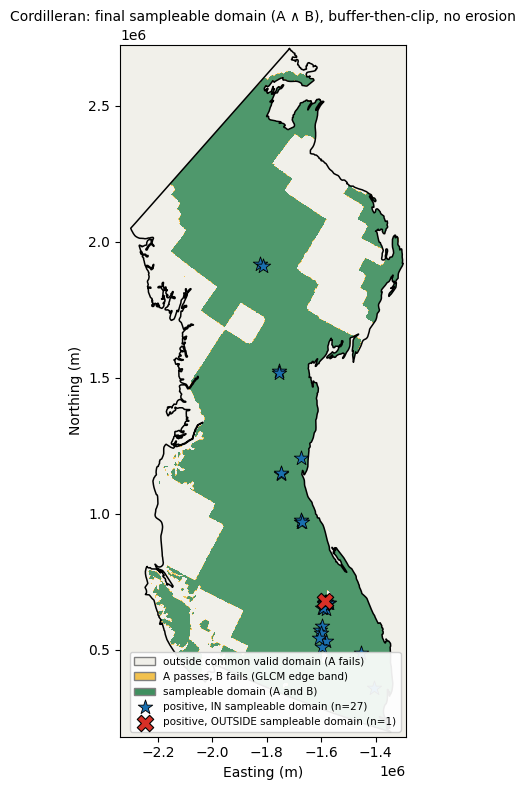

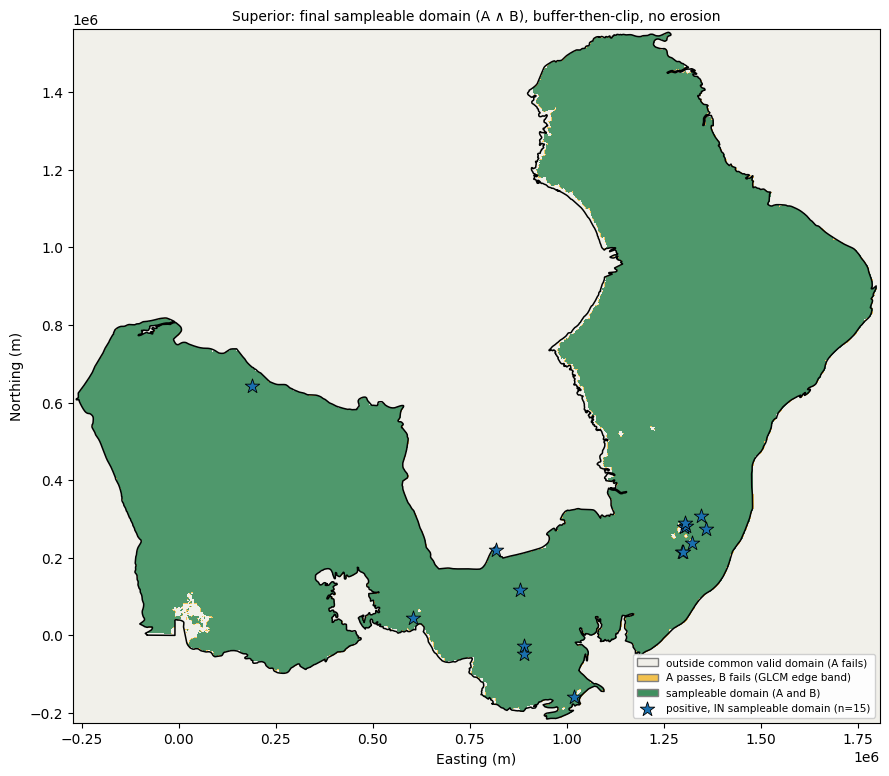

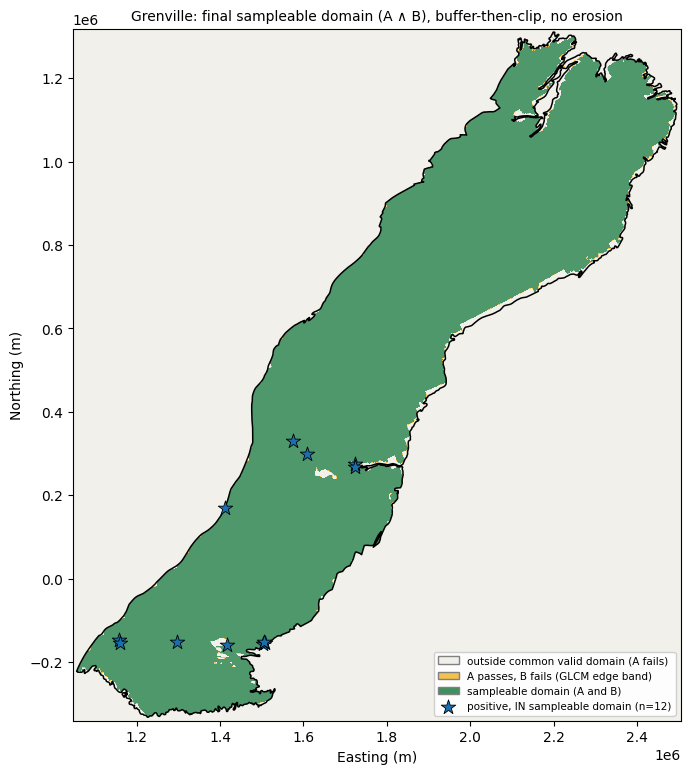

In [14]:
def plot_sampleable(name):
    d = COV[name]
    ref_tf, shape = d['ref_tf'], d['ref_shape']
    H, W = shape
    extent = [ref_tf.c, ref_tf.c + W * ref_tf.a, ref_tf.f + H * ref_tf.e, ref_tf.f]

    fig, ax = plt.subplots(figsize=(9, 8))
    bg = np.zeros(shape, dtype=int)
    bg[d['common_final']] = 1                              # A passed, B not yet checked
    bg[d['sampleable']]   = 2                               # A and B (final sampleable domain)
    cmap = mcolors.ListedColormap(['#f0efe9', '#f2c14e', '#3f8f5f'])
    ax.imshow(bg, extent=extent, origin='upper', cmap=cmap, vmin=0, vmax=2, alpha=0.92)

    boundary = gpd.read_file(REGIONS[name]['outline']).to_crs(PROJECTED_CRS)
    for geom in boundary.geometry:
        polys = [geom] if geom.geom_type == 'Polygon' else list(geom.geoms)
        for poly in polys:
            gx, gy = poly.exterior.xy
            ax.plot(gx, gy, 'k-', lw=1.1)

    tr = pyproj.Transformer.from_crs('EPSG:4326', PROJECTED_CRS, always_xy=True)
    pos = d['pos']
    rc = recheck_df[recheck_df['region'] == name].reset_index(drop=True)
    ok = rc['in_sampleable'].values
    px_, py_ = tr.transform(pos['lon'].values, pos['lat'].values)
    ax.scatter(px_[ok], py_[ok], s=120, marker='*', c='#1a6faf',
              edgecolors='black', linewidths=0.6, zorder=5,
              label=f'positive, IN sampleable domain (n={int(ok.sum())})')
    if (~ok).any():
        ax.scatter(px_[~ok], py_[~ok], s=140, marker='X', c='#d73027',
                  edgecolors='black', linewidths=0.8, zorder=6,
                  label=f'positive, OUTSIDE sampleable domain (n={int((~ok).sum())})')

    legend_extra = [
        mpatches.Patch(facecolor='#f0efe9', edgecolor='grey', label='outside common valid domain (A fails)'),
        mpatches.Patch(facecolor='#f2c14e', edgecolor='grey', label='A passes, B fails (GLCM edge band)'),
        mpatches.Patch(facecolor='#3f8f5f', edgecolor='grey', label='sampleable domain (A and B)'),
    ]
    h, l = ax.get_legend_handles_labels()
    ax.legend(handles=legend_extra + h, loc='lower right', fontsize=7.5, framealpha=0.92)
    ax.set_title(f'{name}: final sampleable domain (A ∧ B), buffer-then-clip, no erosion', fontsize=10)
    ax.set_xlabel('Easting (m)'); ax.set_ylabel('Northing (m)'); ax.set_aspect('equal')
    plt.tight_layout(); plt.show()

for name in REGIONS:
    plot_sampleable(name)

## 15. Candidate/background point counts inside the final sampleable domain

`N_BACKGROUND` / `N_UNLABELED` below mirror the official modeling
notebook's values (`eval_neg` + `train_unlabeled`, disjoint pools) -- this
notebook does not import them, so they are restated here for the
comparison, matching the official pipeline's numbers.

In [15]:
N_BACKGROUND = 4000   # matches the official pipeline's eval_neg pool size
N_UNLABELED  = 4000   # matches the official pipeline's train_unlabeled pool size
N_NEEDED = N_BACKGROUND + N_UNLABELED

def count_in_sampleable(name, df):
    d = COV[name]
    ref_tf, ref_crs, ref_shape = d['ref_tf'], d['ref_crs'], d['ref_shape']
    tr = pyproj.Transformer.from_crs('EPSG:4326', ref_crs, always_xy=True)
    xs, ys = tr.transform(df['lon'].values, df['lat'].values)
    rows, cols = rio_rowcol(ref_tf, xs, ys)
    rows = np.asarray(rows); cols = np.asarray(cols)
    H, W = ref_shape
    in_bounds = (rows >= 0) & (rows < H) & (cols >= 0) & (cols < W)
    ok = np.zeros(len(df), dtype=bool)
    ok[in_bounds] = d['sampleable'][rows[in_bounds], cols[in_bounds]]
    return int(ok.sum())

print(f'Requirement (mirrors official pipeline): N_BACKGROUND({N_BACKGROUND}) + N_UNLABELED({N_UNLABELED}) '
      f'= {N_NEEDED} disjoint candidate points needed per region.\n')

cand_rows = []
for name in REGIONS:
    cand = COV[name]['cand']
    n_total = len(cand)
    n_ok = count_in_sampleable(name, cand)
    enough = n_ok >= N_NEEDED
    cand_rows.append({'region': name, 'n_candidates_total': n_total,
                      'n_in_sampleable_domain': n_ok,
                      'pct_in_sampleable': n_ok / n_total * 100,
                      f'enough_for_{N_NEEDED}': enough})
    flag = 'OK' if enough else f'SHORTFALL of {N_NEEDED - n_ok}'
    print(f'[{name}] candidates total={n_total}  in sampleable domain={n_ok} '
         f'({n_ok/n_total*100:.1f}%)  need={N_NEEDED}  -> {flag}')

cand_df = pd.DataFrame(cand_rows)
print()
print(cand_df.round(2).to_string(index=False))

Requirement (mirrors official pipeline): N_BACKGROUND(4000) + N_UNLABELED(4000) = 8000 disjoint candidate points needed per region.

[Cordilleran] candidates total=22724  in sampleable domain=16316 (71.8%)  need=8000  -> OK
[Superior] candidates total=19702  in sampleable domain=19371 (98.3%)  need=8000  -> OK
[Grenville] candidates total=8752  in sampleable domain=8524 (97.4%)  need=8000  -> OK

     region  n_candidates_total  n_in_sampleable_domain  pct_in_sampleable  enough_for_8000
Cordilleran               22724                   16316              71.80             True
   Superior               19702                   19371              98.32             True
  Grenville                8752                    8524              97.39             True
